# Datos y análisis exploratorio

**Demanda:** XM (operador del mercado eléctrico colombiano), API pública de Sinergox, métrica *Demanda Comercial por Mercado de Comercialización*, mercado **CARIBE SOL**: el área de Air-e (Atlántico, Magdalena y La Guajira), que existe desde el 1 de octubre de 2020. Resolución horaria.

**Clima:** NASA POWER, serie horaria del punto de Sabanagrande (10,79° N, −74,76° O), en hora local: temperatura a 2 m, humedad relativa, viento y lluvia.

**Calendario:** festivos oficiales de Colombia (paquete `holidays`), días antes y después de festivo, temporada de fin de año.

In [1]:
import sys, json, warnings; warnings.filterwarnings("ignore")
sys.path.insert(0, "../src"); import estilo_tablas; estilo_tablas.activar(); import pipeline_energia as P
import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 30)
R = "../resultados/"
plt.rcParams.update({"figure.figsize": (10, 4), "axes.spines.top": False, "axes.spines.right": False})
COL = {"Persistencia (misma hora de ayer)": "#9AA5A0", "Estacional (misma hora semana pasada)": "#B8C2BD", "Promedio por hora y día": "#D5DBD8",
       "Ridge (lineal)": "#5B7F96", "Random forest (relativo)": "#1F5A3A", "XGBoost (relativo)": "#C8892B", "Híbrido Ridge + XGBoost (residuo relativo)": "#8E4B7A"}

In [2]:
df = pd.read_pickle(R + "datos_horarios.pkl")
print("Horas:", len(df), "| desde", df.index.min(), "hasta", df.index.max())
print("Horas de demanda faltantes:", int(df.mwh.isna().sum()))
df.mwh.describe().round(1)

Horas: 52944 | desde 2020-10-01 00:00:00 hasta 2026-10-15 23:00:00
Horas de demanda faltantes: 0


count    52944.0
mean      1209.6
std        165.4
min        758.7
25%       1092.1
50%       1193.1
75%       1312.7
max       1827.7
Name: mwh, dtype: float64

In [3]:
a = df.mwh.resample("YE").agg(["mean", "max"]); a.index = a.index.year
a["energia_GWh"] = df.mwh.resample("YE").sum().values / 1e3; a.round(1)

mean,max,energia_GWh
1.060,1.314,2.341
1.107,1.402,9.699
1.111,1.401,9.729
1.176,1.540,10.305
1.227,1.582,10.781
1.301,1.675,11.400
1.416,1.828,9.786


Crecimiento de la demanda media 2021 → 2025: 17.5 %


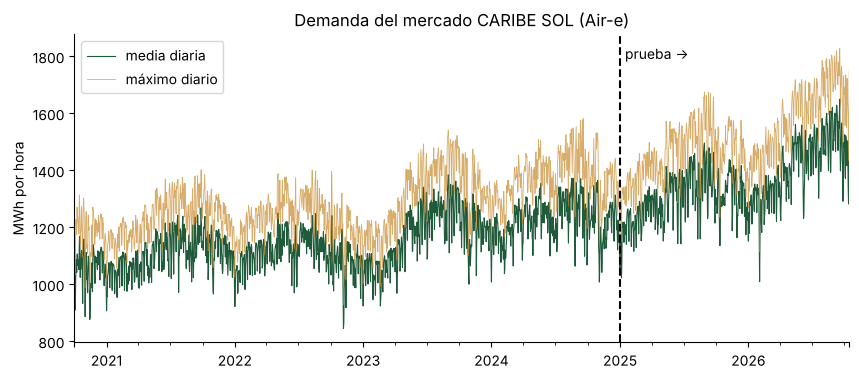

In [4]:
print("Crecimiento de la demanda media 2021 → 2025: %.1f %%" % (100*(df.mwh["2025"].mean()/df.mwh["2021"].mean()-1)))
fig, ax = plt.subplots(); df.mwh.resample("D").mean().plot(ax=ax, lw=.8, color="#1F5A3A", label="media diaria")
df.mwh.resample("D").max().plot(ax=ax, lw=.6, color="#C8892B", alpha=.7, label="máximo diario")
ax.axvline(pd.Timestamp("2025-01-01"), color="k", ls="--"); ax.text(pd.Timestamp("2025-01-15"), df.mwh.max()*.98, "prueba →")
ax.set_ylabel("MWh por hora"); ax.set_title("Demanda del mercado CARIBE SOL (Air-e)"); ax.legend(); plt.show()

 **Hallazgo 1 — tendencia fuerte.** La demanda media creció 17,5 % entre 2021 y 2025 y sigue subiendo en 2026: el periodo de prueba tiene niveles **nunca vistos** en el entrenamiento. Esto obliga a diseñar modelos que no dependan de haber visto ese nivel (capítulo 2).

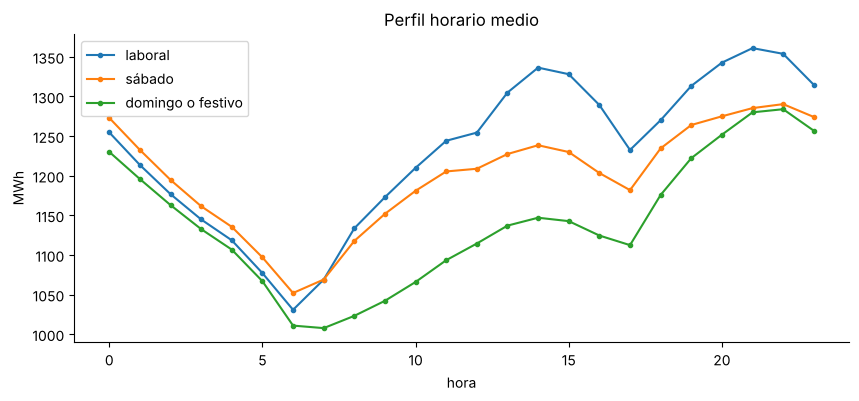

Festivo frente a día laboral (media): -7.4 %


In [5]:
X, y = P.construir(df, expost=True)
perf = y.groupby([X.tipo_dia, X.hora]).mean().unstack(0); perf.columns = ["laboral", "sábado", "domingo o festivo"]
fig, ax = plt.subplots(); perf.plot(ax=ax, marker="o", ms=3); ax.set_xlabel("hora"); ax.set_ylabel("MWh"); ax.set_title("Perfil horario medio"); plt.show()
print("Festivo frente a día laboral (media): %.1f %%" % (100*(y[X.festivo == 1].mean()/y[(X.festivo == 0) & (X.dow < 5)].mean()-1)))

 **Hallazgo 2 — calendario.** En días laborales la demanda tiene dos picos: la tarde (13–15 h, el calor del día) y la noche (20–22 h, aire acondicionado e iluminación en los hogares); un festivo consume 7,4 % menos que un día laboral. "La misma hora de ayer" falla justo después y antes de un festivo.

In [6]:
m = X.hora.between(13, 16) & (X.tipo_dia == 0)
b = pd.cut(X.calor[m], [20, 30, 34, 38, 42, 46])
t = y[m].groupby(b).agg(["mean", "count"]).round(0); t["vs_<=30°C_%"] = (100*(t["mean"]/t["mean"].iloc[0]-1)).round(1); t

,mean,count,vs_<=30°C_%
calor,,,
"(20, 30]",1127.000000,82,0.000000
"(30, 34]",1236.000000,2.093,9.700000
"(34, 38]",1349.000000,3.155,19.700000
"(38, 42]",1437.000000,581,27.500000
"(42, 46]",1464.000000,1,29.900000


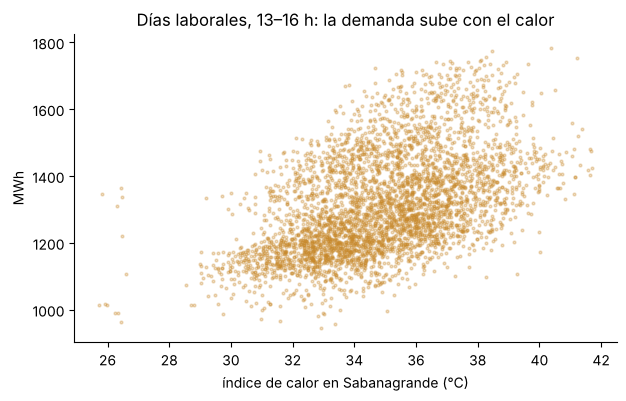

In [7]:
fig, ax = plt.subplots(figsize=(7, 4)); s = X[m].sample(4000, random_state=1)
ax.scatter(s.calor, y[s.index], s=4, alpha=.3, color="#C8892B"); ax.set_xlabel("índice de calor en Sabanagrande (°C)"); ax.set_ylabel("MWh")
ax.set_title("Días laborales, 13–16 h: la demanda sube con el calor"); plt.show()

 **Hallazgo 3 — calor no lineal.** En días laborales de 13 a 16 h, con índice de calor de 34–38 °C la demanda es 19,7 % mayor que con 30 °C o menos, y con 38–42 °C, 27,5 % mayor. La relación se curva: un modelo lineal la captura solo en parte; los árboles la aprenden sola.

In [8]:
print("Autocorrelación horaria — rezago 24 h: %.3f | 168 h: %.3f" % (y.autocorr(24), y.autocorr(168)))
Xo, yo = P.construir(df); ok = Xo.notna().all(axis=1)
print("Filas utilizables (con todas las predictoras):", int(ok.sum()), "| predictoras:", Xo.shape[1])
assert "mwh" not in Xo.columns
pd.Series(Xo.columns, name="predictoras").to_frame().T

Autocorrelación horaria — rezago 24 h: 0.897 | 168 h: 0.876


Filas utilizables (con todas las predictoras): 52272 | predictoras: 28


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27
predictoras,hora,dow,mes,festivo,dia_antes_festivo,dia_despues_festivo,tipo_dia,doy_sin,doy_cos,hora_sin,hora_cos,navidad,t,lag24,lag48,lag168,lag336,media_dia_ant,max_dia_ant,media_7d,media_misma_hora_4sem,T2M,RH2M,WS2M,calor,tmax_dia,lluvia_24h,calor_x_hora


 **Predictoras (todas conocidas al emitir el pronóstico, al final del día anterior):** calendario (hora, día, mes, festivos, temporada, armónicos), historia de la demanda con rezagos de 24 h o más (misma hora de ayer, de anteayer, de la semana pasada y de hace dos semanas; media y máximo de ayer; media de 7 días; media de la misma hora en 4 semanas) y clima de Sabanagrande **del día anterior** (temperatura, humedad, viento, índice de calor, lluvia de 24 h). Como sensibilidad se prueba también con el clima real del día pronosticado ("pronóstico del tiempo perfecto").

**Tamaño:** 52.272 filas horarias utilizables, por encima de las ~20.000 que sugiere la guía.